In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

In [6]:
df = pd.read_csv("../data/raw/bank-additional-full.csv")

X = df.drop(columns=["deposit", "duration"])
y = df["deposit"]

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["str", "object"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

dummy_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]
)

dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_test)

In [8]:
y_score_dummy = dummy_model.predict_proba(X_test)[:, 1]

dummy_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_dummy),
    "Precision": precision_score(y_test, y_pred_dummy, pos_label="yes", zero_division=0),
    "Recall": recall_score(y_test, y_pred_dummy, pos_label="yes", zero_division=0),
    "F1-score": f1_score(y_test, y_pred_dummy, pos_label="yes", zero_division=0),
    "ROC-AUC": roc_auc_score(y_test == "yes", y_score_dummy),
    "PR-AUC": average_precision_score(y_test == "yes", y_score_dummy)
}

print(pd.Series(dummy_metrics).round(4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_dummy, labels=["no", "yes"]))

Accuracy     0.5262
Precision    0.0000
Recall       0.0000
F1-score     0.0000
ROC-AUC      0.5000
PR-AUC       0.4738
dtype: float64

Matrice de confusion :
[[1175    0]
 [1058    0]]


On gardera notre DummyClassifier de cote pour la suite, mais passons a d'autres modeles.

Model Logistic Regression :

In [9]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['no','yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remain

In [10]:
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = logistic_model.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()

coef_df = coef_df.sort_values(
    "abs_coefficient",
    ascending=False
)

print(coef_df.head(15))

                  feature  coefficient  abs_coefficient
48  cat__poutcome_success     1.527719         1.527719
41         cat__month_mar     1.323291         1.323291
36         cat__month_dec     1.225137         1.225137
38         cat__month_jan    -1.004717         1.004717
43         cat__month_nov    -0.815083         0.815083
35         cat__month_aug    -0.736938         0.736938
44         cat__month_oct     0.706315         0.706315
33   cat__contact_unknown    -0.698178         0.698178
14       cat__job_student     0.664866         0.664866
45         cat__month_sep     0.646017         0.646017
39         cat__month_jul    -0.589890         0.589890
46  cat__poutcome_failure    -0.587553         0.587553
49  cat__poutcome_unknown    -0.556598         0.556598
31  cat__contact_cellular     0.528223         0.528223
37         cat__month_feb    -0.484333         0.484333


Analyse de ce tableau, pour rappel : 
- Coefficient positif : la variable est associee à des chances de souscription plus elevees.
- Coefficient negatif : la variable est associee à des chances de souscription plus faibles.
- Coefficient proche de zero : la variable apporte peu de variation dans les predictions, toutes choses egales par ailleurs.
Notre colonne abs_coef permet de voir a quel point une variable influe notre resultat, en yes ou no.

Ces resultats rejoignent nos observations faites pendant l'EDA, ou nous avions remarque qu'un poutcome success ou encore le mois avaient un role important pour notre prediction.

### Analyse des coefficients de la régression logistique

L'analyse des coefficients met en évidence plusieurs variables associées aux prédictions de souscription.

La variable `poutcome_success` présente le coefficient positif le plus élevé (+1,528). Cela suggère que les clients ayant souscrit lors d'une campagne précédente ont des chances estimées de souscription plus élevées que ceux appartenant à la catégorie de référence (`other`). L'historique des campagnes semble donc constituer une information particulièrement pertinente.

Le mois de contact apparaît également comme une caractéristique importante. Les mois de mars (+1,323) et décembre (+1,225) présentent des coefficients positifs élevés, tandis que janvier (-1,005), novembre (-0,815) et août (-0,737) présentent des coefficients négatifs. Ces observations rejoignent les tendances identifiées lors de l'analyse exploratoire des données. Il faut néanmoins interpréter certains résultats avec prudence, notamment pour décembre, qui comporte relativement peu d'observations.

Enfin, le canal de contact et la profession semblent également apporter de l'information. Les contacts par téléphone mobile (`cellular`) et les clients étudiants (`student`) présentent des coefficients positifs.

Globalement, ces résultats suggèrent que l'historique des campagnes, la période de contact et certaines caractéristiques des clients sont associés à la probabilité de souscription estimée par le modèle.

Ces coefficients décrivent des associations conditionnelles et ne démontrent pas de relations causales. Leur interprétation dépend également des catégories de référence utilisées pour l'encodage des variables catégorielles.

On va faire un graphique pour mieux visualiser les coef

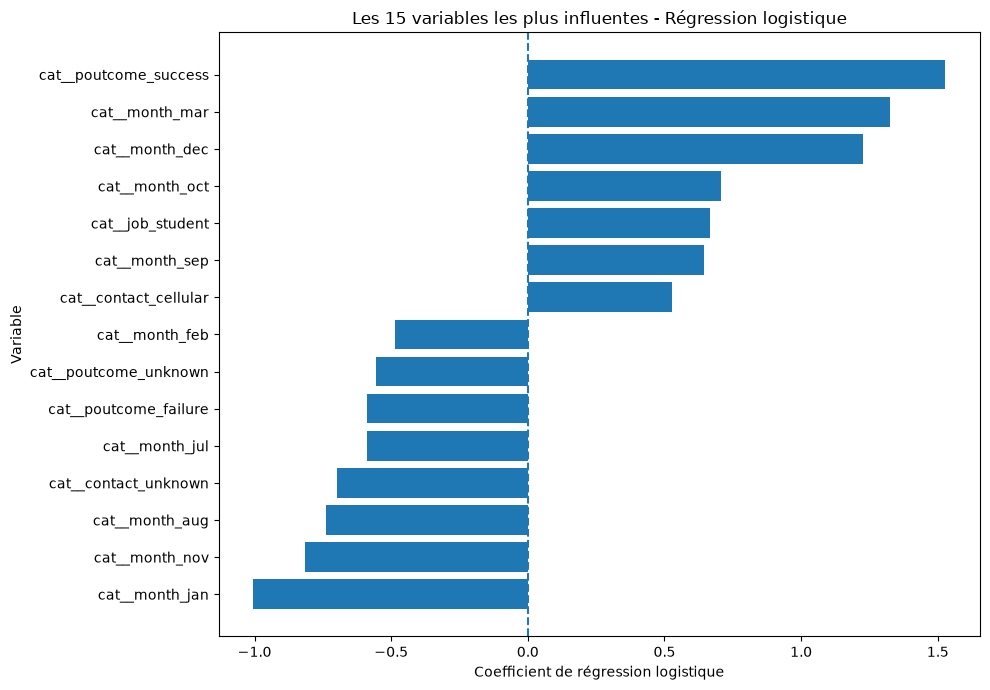

In [11]:
import matplotlib.pyplot as plt

plot_df = (
    coef_df.nlargest(15, "abs_coefficient")
    .sort_values("coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["feature"],
    plot_df["coefficient"]
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Coefficient de régression logistique")
plt.ylabel("Variable")
plt.title("Les 15 variables les plus influentes - Régression logistique")

plt.tight_layout()
plt.show()

Regardons maintenant les predictions de notre modele :

In [12]:
y_pred_logistic = logistic_model.predict(X_test)

y_proba_logistic = logistic_model.predict_proba(X_test)[:, 1]

In [13]:
from sklearn.preprocessing import LabelBinarizer

y_test_binary = (y_test == "yes").astype(int)

pr_auc = average_precision_score(y_test_binary, y_proba_logistic)

print("PR-AUC :", pr_auc)

PR-AUC : 0.7591393145404125


In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report

print("Accuracy :", accuracy_score(y_test, y_pred_logistic))
print("Precision :", precision_score(y_test, y_pred_logistic, pos_label="yes"))
print("Recall :", recall_score(y_test, y_pred_logistic, pos_label="yes"))
print("F1-score :", f1_score(y_test, y_pred_logistic, pos_label="yes"))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_logistic))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_logistic, labels=["no", "yes"]))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_logistic))

Accuracy : 0.6954769368562472
Precision : 0.7327586206896551
Recall : 0.5623818525519849
F1-score : 0.6363636363636364
ROC-AUC : 0.7578546434460846

Matrice de confusion :
[[958 217]
 [463 595]]

Rapport de classification :
              precision    recall  f1-score   support

          no       0.67      0.82      0.74      1175
         yes       0.73      0.56      0.64      1058

    accuracy                           0.70      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.70      0.70      0.69      2233



On remarque quelque chose d'important, notre modele reconnaît mieux les clients qui ne souscrivent pas (recall = 0,82) que ceux qui souscrivent (recall = 0,56).

Bilan de la regression logistique : 
Le modèle identifie correctement une majorité des clients, mais manque encore environ 44 % des souscripteurs réels. Sa precision de 73,28 % indique néanmoins que ses prédictions positives sont plutôt fiables.
Les coefficients montrent notamment l'importance de certaines variables comme le résultat d'une campagne précédente (poutcome), le mois de contact et la profession.
Donc pour conclure, la régression logistique constitue un premier modèle de référence intéressant. Ses performances restent perfectibles, notamment sur la détection des souscripteurs. 
On va maintenant tester un Decision Tree afin de comparer les performances et la capacité à capturer des relations non linéaires.

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(random_state=42))
    ]
)

param_grid = {
    "model__max_leaf_nodes": [5, 10, 20, 30, 50, None],
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_leaf": [1, 5, 10, 20]
}

grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleur ROC-AUC en validation croisée :", grid_search.best_score_)

Meilleurs paramètres : {'model__max_depth': 10, 'model__max_leaf_nodes': 50, 'model__min_samples_leaf': 5}
Meilleur ROC-AUC en validation croisée : 0.7617661053517685


Toujours important de faire un test des meilleurs parametres pour eviter l'overfitting (ou l'inverse).
Notre meilleur ROC-AUC est environ 0.762, on fait le parallele avec notre ancien model de regression logistique, qui lui avait obtenu 0.758.
A savoir qu'un ROC-AUC de 0,762 signifie notamment qu'en prenant au hasard un client yes et un client no, le modele attribuera au client yes un score de souscription supérieur dans environ 76,2 % des paires, ce qui est bon, mais pas excellent. Il nous reste une marge d'amelioration qui est quand meme importante.
Regardons l'evaluation complete de notre DecisionTree et comparons le a celle de la regression logistique :


In [16]:
best_tree = grid_search.best_estimator_

y_pred_tree = best_tree.predict(X_test)
y_proba_tree = best_tree.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_tree))
print("Precision :", precision_score(y_test, y_pred_tree, pos_label="yes"))
print("Recall :", recall_score(y_test, y_pred_tree, pos_label="yes"))
print("F1-score :", f1_score(y_test, y_pred_tree, pos_label="yes"))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_tree))
print("PR-AUC :", average_precision_score(y_test_binary, y_proba_tree))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_tree, labels=["no", "yes"]))

Accuracy : 0.7133900582176445
Precision : 0.7693298969072165
Recall : 0.5642722117202268
F1-score : 0.6510359869138496
ROC-AUC : 0.7630591642199253
PR-AUC : 0.7435561939092411

Matrice de confusion :
[[996 179]
 [461 597]]


Le Decision Tree identifie a peu pres autant de clients interesses que la regression logistique, mais ses predictions positives sont plus fiables. En revanche, il manque toujours 461 clients qui auraient souscrit, soit environ 43,6 % des souscripteurs reels.
Mais, le Decision Tree est legerement meilleur sur la plupart des metriques, notamment Precision. Toutefois, aucun des deux modeles ne detecte encore suffisamment de souscripteurs potentiels

Continuons avec le model de Random Forest :

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_pipeline.fit(X_train, y_train)

y_pred_rf = random_forest_pipeline.predict(X_test)
y_proba_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision :", precision_score(y_test, y_pred_rf, pos_label="yes"))
print("Recall :", recall_score(y_test, y_pred_rf, pos_label="yes"))
print("F1-score :", f1_score(y_test, y_pred_rf, pos_label="yes"))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_rf))
print("PR-AUC :", average_precision_score(y_test_binary, y_proba_rf))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_rf, labels=["no", "yes"]))

Accuracy : 0.7241379310344828
Precision : 0.7494356659142212
Recall : 0.6275992438563327
F1-score : 0.6831275720164609
ROC-AUC : 0.7794602421268552
PR-AUC : 0.7748508249731407

Matrice de confusion :
[[953 222]
 [394 664]]


Ok, la Random Forest obtient les meilleurs resultats sur 5 des 6 metriques :
- Elle détecte 62,76 % des clients qui souscrivent réellement, contre environ 56 % pour les deux autres modèles.
- Sa Precision est de 74,94 % : environ 3 prédictions positives sur 4 correspondent à de vrais souscripteurs.
- Son F1-score de 68,31 % montre un meilleur équilibre entre Precision et Recall.
- Son ROC-AUC de 0,779 est également le meilleur.

La Random Forest est notre meilleur modèle actuel. Elle détecte davantage de souscripteurs potentiels, ce qui correspond à notre priorité métier.
La Decision Tree conserve toutefois une meilleure Precision (76,93 %). Si la banque veut réduire les sollicitations inutiles, elle reste intéressante.

On va donc maintenant essayer d'optimiser notre Random Forest pour continuer d'ameliorer ses metriques :

In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score

rf_pipeline_tuning = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=1
        ))
    ]
)

param_grid_rf = {
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": ["sqrt"]
}

recall_scorer = make_scorer(recall_score, pos_label="yes")

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline_tuning,
    param_grid=param_grid_rf,
    scoring=recall_scorer,
    cv=5,
    n_jobs=-1
)

grid_search_rf.fit(X_train, y_train)

print("Meilleurs paramètres :", grid_search_rf.best_params_)
print("Meilleur Recall en validation croisée :", grid_search_rf.best_score_)

Meilleurs paramètres : {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Meilleur Recall en validation croisée : 0.6475997889924388


On remarque que notre Recall a augmenté grâce à cette optimisation, ce qui n'est pas négligeable, mais ce n'est pas encore suffisant. La validation croisée nous donne un Recall moyen de **64,76 %**, ce qui signifie que le modèle détecte environ 65 % des clients qui souscrivent réellement.

Les paramètres retenus permettent aux arbres de se développer sans limite de profondeur prédéfinie, avec des feuilles potentiellement très petites.

Il faudra maintenant évaluer cette Random Forest optimisée sur notre jeu de test afin de vérifier si cette amélioration se confirme sur des données jamais vues et de comparer ses performances avec notre modèle initial.


In [19]:
best_rf = grid_search_rf.best_estimator_

y_pred_rf_optimized = best_rf.predict(X_test)
y_proba_rf_optimized = best_rf.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_rf_optimized))
print("Precision :", precision_score(y_test, y_pred_rf_optimized, pos_label="yes"))
print("Recall :", recall_score(y_test, y_pred_rf_optimized, pos_label="yes"))
print("F1-score :", f1_score(y_test, y_pred_rf_optimized, pos_label="yes"))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_rf_optimized))
print("PR-AUC :", average_precision_score(y_test_binary, y_proba_rf_optimized))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_rf_optimized, labels=["no", "yes"]))

Accuracy : 0.7223466188983431
Precision : 0.7444196428571429
Recall : 0.6304347826086957
F1-score : 0.6827021494370522
ROC-AUC : 0.7788022362546757
PR-AUC : 0.7731193693324819

Matrice de confusion :
[[946 229]
 [391 667]]


Ok l'optimisation ameliore legerement le Recall mais ca reste tres faible.
Et meme, la random forest initiale reste meilleure sur plusieurs metriques...
Cela peut sembler illogique, on optimise notre foret mais elle est moins efficace sur le jeu de test.
Mais en effet, il faut retenir que le meilleur résultat en validation croisée ne garantit pas le meilleur résultat sur des données inédites.

En soit avec notre optimisation on a recupere 3 clients sur les 1058. C'est bien, mais ce n'est toujours pas assez, on passe a cote de trop d'autres clients.
La matrice de confusion le montre, on a encore 229 de faux positifs, et 391 de faux negatifs.

Dans notre cas, notre modele predit yes si sa proba estimee depasse 0.5. C'est nous qui avons choisi ce seuil, mais il n'est pas obligatoire, alors regardons si il est interessant de le modifier.

En effet, il y a des avantages et desavantages, regardons deja les avantages :
Partons du principe que l'on ait decide de baisser le seuil a 30%:

la banque contacte plus de client si on baisse le seuil, elle evite d'ecarter des clients ayaient une proba de 40 ou 45%, ce qui reste un bon pourcentage.
Donc en gros, On fait baisser le faux negatif.

Mais en contrepartie, on augmente le faux positif ! Si notre client avait une proba de 31%, ce n'etait peut etre pas un hasard, notre modele avait surement bien predit sa probabilite de souscrire, avec un seuil a 30%, il est quand meme inclus dans les clients potentiels et seront donc sur la liste a contacter.
Cela risque donc de diminuer notre precision.

Comparons les differents resultats en testant differents seuils avec notre random forest initiale :

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

thresholds = [0.5, 0.4, 0.3, 0.2]

results = []

for threshold in thresholds:
    y_pred_threshold = np.where(
        y_proba_rf >= threshold,
        "yes",
        "no"
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=["no", "yes"]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_threshold, pos_label="yes"),
        "Recall": recall_score(y_test, y_pred_threshold, pos_label="yes"),
        "F1-score": f1_score(y_test, y_pred_threshold, pos_label="yes"),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Total Targeted": fp + tp
    })

threshold_results = pd.DataFrame(results)

threshold_results

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,True Positives,Total Targeted
0,0.5,0.745819,0.632325,0.684399,228,389,669,897
1,0.4,0.669231,0.740076,0.702873,387,275,783,1170
2,0.3,0.591837,0.849716,0.697711,620,159,899,1519
3,0.2,0.526899,0.944234,0.676371,897,59,999,1896


On confirme bien les hypotheses faites au dessus !
le recall augmente, mais la banque doit gerer de plus en plus de faux positifs, ce qui peut avoir des couts importants qui serait evitable.

On va donc faire un Threshold Optimization (optimisation du seuil de décision).
Notre objectif est d'atteindre le meilleur recall possible tout en limitant les faux positifs.

In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

y_proba_cv = cross_val_predict(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

y_train_binary = (y_train == "yes").astype(int)

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results_cv = []

for threshold in thresholds:
    y_pred = (y_proba_cv >= threshold).astype(int)

    precision = precision_score(y_train_binary, y_pred, zero_division=0)
    recall = recall_score(y_train_binary, y_pred)

    threshold_results_cv.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall
    })

threshold_df_cv = pd.DataFrame(threshold_results_cv)

eligible_thresholds = threshold_df_cv[
    threshold_df_cv["Recall"] >= 0.75
]

best_threshold = eligible_thresholds.loc[
    eligible_thresholds["Precision"].idxmax()
]

print(best_threshold)

Threshold    0.400000
Precision    0.661951
Recall       0.752068
Name: 30, dtype: float64


On vient de tester 81 seuils differents, est le plus optimal est donc 0.40 !

Testons le maintenant sur notre jeu de test

In [22]:
y_pred_rf_04 = np.where(
    y_proba_rf >= best_threshold["Threshold"],
    "yes",
    "no"
)

print("Precision :", precision_score(y_test, y_pred_rf_04, pos_label="yes"))
print("Recall :", recall_score(y_test, y_pred_rf_04, pos_label="yes"))
print("F1-score :", f1_score(y_test, y_pred_rf_04, pos_label="yes"))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_rf_04, labels=["no", "yes"]))

Precision : 0.6692307692307692
Recall : 0.7400756143667296
F1-score : 0.7028725314183124

Matrice de confusion :
[[788 387]
 [275 783]]


Petit bilan sur ce treshold opti : 
on detecte 119 souscripteurs supplementaires
on evite 119 faux negatifs

En contrepartie, 165 clients supplementaires sont contactes inutilement, il faut donc voir si les couts appliques a ces 165 contacts sont negligeables face au benefice cree avec ce nouveau seuil.
Dans notre cas c'est difficile de le savoir etant donne qu'on ne connait pas le cout des appels, les salaires des employes, etc... Mais il serait interessant de le faire pour immerger encore plus notre travail dans un monde reel et non fictif.

Ok on va maintenant regarder quelles variables notre Random Forest utilise le plus pour effectuer ses predictions et voir si c'est coherent avec notre EDA et nos querys. Pour ca, on utilise notre random forest avec un seuil de 0.40, celui qu'on a calcule le plus optimal.
De plus, on va les regrouper en reformer nos variables de base avant le OHE. Ce qui permettra d'avoir moins de variables et plus de groupes, mais aussi d'avoir quelque chose de plus coherent vis a vis de notre EDA.


In [23]:
feature_names = random_forest_pipeline.named_steps["preprocessor"].get_feature_names_out()

importances = random_forest_pipeline.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)


importance_df["Original_Feature"] = importance_df["Feature"].str.replace(
    r"^(num__|cat__)",
    "",
    regex=True
).str.split("_").str[0]

grouped_importance = (
    importance_df.groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_importance


,Original_Feature,Importance
0,balance,0.151716
1,age,0.131817
2,day,0.116991
3,month,0.116044
4,job,0.101169
5,campaign,0.064781
6,poutcome,0.057385
7,contact,0.050238
8,education,0.048135
9,pdays,0.040183


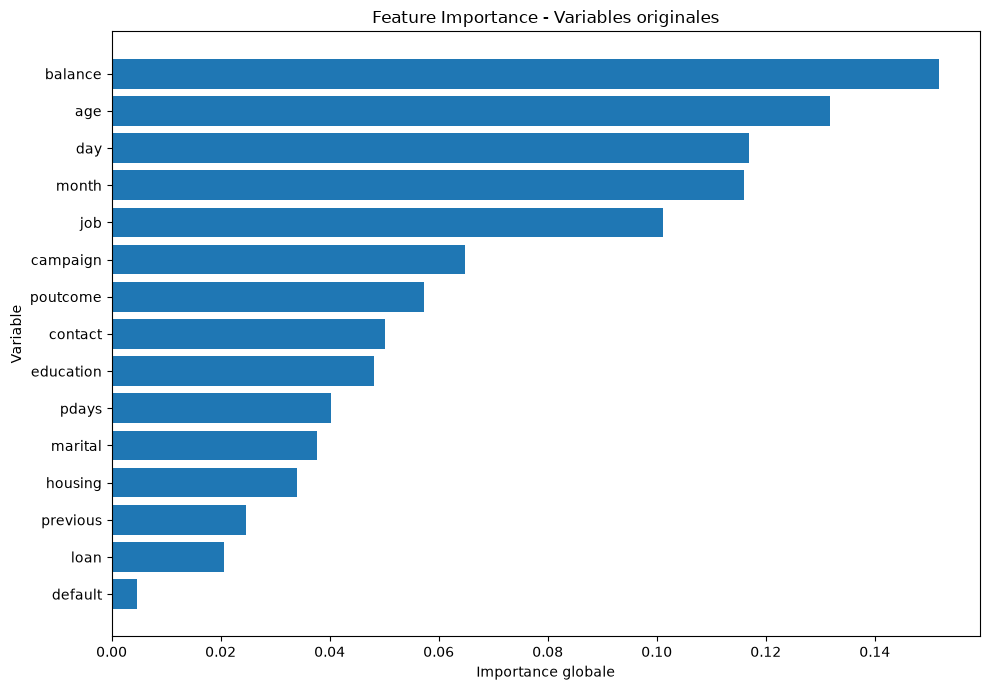

In [24]:
grouped_plot = grouped_importance.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    grouped_plot["Original_Feature"],
    grouped_plot["Importance"]
)
plt.xlabel("Importance globale")
plt.ylabel("Variable")
plt.title("Feature Importance - Variables originales")
plt.tight_layout()
plt.show()

Cela reste globalement coherent avec les tendances observees durant notre EDA !
Voici une synthese finale IA qui reprend tout ce qui a ete fait dans cette partie, tout a ete lu et verifiee avec les informations ecrites a la main durant tout ce notebook. L'utilisation de l'IA ici permet juste d'eviter de perdre du temps pour des infos deja exprimees.

## Conclusion – Phase 5 : Modélisation et entraînement

Durant cette phase, plusieurs modèles de classification ont été entraînés et évalués afin de prédire si un client souscrira à un dépôt à terme (`deposit = yes`).

Trois modèles ont été étudiés :
- **Logistic Regression** : premier modèle de référence, permettant également d'interpréter l'influence des variables à travers ses coefficients.
- **Decision Tree** : modèle optimisé avec `GridSearchCV` afin de trouver une configuration plus performante.
- **Random Forest** : modèle ayant obtenu les meilleures performances globales parmi les modèles testés.

Le Random Forest initial a obtenu les résultats suivants sur le jeu de test :
- Accuracy : **72,41 %**
- Precision : **74,94 %**
- Recall : **62,76 %**
- F1-score : **68,31 %**
- ROC-AUC : **0,779**
- PR-AUC : **0,775**

Une optimisation des hyperparamètres a ensuite été réalisée avec `GridSearchCV`. Elle n'a cependant pas apporté d'amélioration significative sur le jeu de test.

Une étude du seuil de classification a également été menée. En abaissant le seuil de 0,5 à 0,4, le Recall passe à environ **74 %**, tandis que la Precision diminue à environ **66,9 %**. Le modèle détecte ainsi davantage de souscripteurs potentiels, au prix d'un plus grand nombre de faux positifs.

Enfin, l'analyse des importances des variables du Random Forest montre que `balance`, `age`, `day`, `month` et `job` figurent parmi les variables les plus importantes pour les prédictions.

**Bilan :** le Random Forest est retenu comme meilleur modèle de notre expérimentation. Il constitue une base satisfaisante pour la suite du projet, tout en présentant des limites : il manque encore une partie des souscripteurs potentiels et ses prédictions doivent être mises en perspective avec les coûts et bénéfices d'une campagne marketing.

In [25]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(random_forest_pipeline, "../models/random_forest.pkl")

['../models/random_forest.pkl']

Ici on enregistre simplement notre pipeline random forest pour pouvoir la reutiliser dans le prochain notebook et ne pas surcharger celui-ci